---

# Tugas Besar 2 IF3170 Inteligensi Artifisial: Logistic Regression

*Notebook bagian Logistic Regression (from scratch) untuk prediksi pembatalan pesanan Ronaldo Hotel. Struktur mengikuti templat notebook tugas besar.*

---

## Kelompok G04: TreeIsAllYouNeed

- Gabriella Botimada Lubis (13524006)
- Agatha Tatianingseto (13524008)
- Muhammad Nur Majiid (13524028)
- Athilla Zaidan Zidna Fann (13524068)
- Reva Natania Sitohang (13524098)

---

## Daftar Isi

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Cost-Sensitive Classification (Bonus)**](#12)
13. [**Algoritma Optimasi: IRLS + Coordinate Descent (Bonus)**](#13)
14. [**Video Kontur Log-Loss (Bonus)**](#14)

---

# Introduction <a name="1"></a>

---

## Overview

*Ronaldo Hotel membutuhkan sistem klasifikasi untuk mengestimasi pesanan yang akan dibatalkan, memakai pembelajaran mesin klasik tanpa sumber daya komputasi sebesar deep learning.*

## Aim

*Notebook ini membangun Logistic Regression from scratch dengan regularisasi L1, L2, dan Elastic Net, memvalidasinya, membandingkannya dengan `scikit-learn`, lalu menghasilkan submisi Kaggle yang reproducible.*

## Metric

***Macro F1-score** adalah metrik kompetisi, yaitu rata-rata F1 kelas batal dan kelas tidak batal. ROC-AUC dan accuracy dilaporkan sebagai pelengkap.*

$$\text{Macro F1} = \frac{F_1^{(0)} + F_1^{(1)}}{2}, \qquad F_1^{(c)} = \frac{2 \cdot \text{Precision}^{(c)} \cdot \text{Recall}^{(c)}}{\text{Precision}^{(c)} + \text{Recall}^{(c)}}$$

## Dataset

*`train.csv` berisi 27.373 pesanan dengan target `is_canceled` (1 = batal), dan `test.csv` berisi 6.844 pesanan tanpa target. Terdapat 17 fitur: 14 numerik (hitungan, lead time, tarif, tanggal, biner) dan 3 kategorikal (`meal_package`, `room_category`, `booking_channel`). Sebagian nilai kosong pada kedua berkas. Analisis lengkap ada di `eda.ipynb`.*

## Approach

*Model: $P(y=1 \mid x) = \sigma(w \cdot x + b)$ dengan $\sigma(z) = 1/(1+e^{-z})$ [15][16]. Bobot dicari dengan Maximum Likelihood, yaitu meminimumkan log-loss (setara memaksimumkan log conditional likelihood) ditambah penalti regularisasi. Dua solver diimplementasikan: mini-batch stochastic gradient descent sesuai materi kuliah [16] dan IRLS + coordinate descent [30] (bagian 13). Solver ikut dipilih lewat validasi silang.*

*Implementasi model ada di `src/algoritma/lr/lr.py` dan preprocessing di `src/algoritma/lr/preprocessing.py`. Fungsi bantu (metrik, split, validasi silang) diambil dari `src/kaggle/lr_submission.py` agar notebook dan skrip menghasilkan submisi yang sama.*

---

# Initialization <a name="2"></a>

---

Bagian ini menyiapkan environment, pengaturan, dan berkas data.

## Environment Setup

Baris instalasi dikomentari secara bawaan.

In [ ]:
# %pip install -q numpy pandas matplotlib scikit-learn

## Import Libraries

Seluruh import notebook diletakkan di sel ini. `scikit-learn` hanya dipakai sebagai pembanding.

In [2]:
import os
import random
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path('..').resolve())) 
sys.path.insert(0, str(Path('.').resolve()))

from algoritma.lr.contour_video import make_video, train_2param
from algoritma.lr.lr import LogisticRegression
from algoritma.lr.preprocessing import (BIN_COLS, CAT_COLS, CONT_COLS, COUNT_COLS, DATE_COLS, FEATURES,
                           ID_COL, LEAD_BINS, TARGET, Preprocessor, drop_duplicates,
                           load_data)
from lr_submission import (COST_FN, COST_FP, COST_THRESHOLDS, GRID, THRESHOLDS, TRAIN_KW,
                           best_cost_threshold, best_threshold, cfg_from_row, compare_sklearn,
                           confusion, cost_threshold, cross_validate, macro_f1, name_of,
                           oof_proba, report, sklearn_model, stratified_holdout, total_cost)

## Settings

Path dan konstanta bersama disimpan di kelas ini.

In [3]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('dataset')
    OUTPUT_DIR = Path('../../output/lr')   
    HOLDOUT    = 0.2

    NEG_COLOR  = '#2a78d6'   
    POS_COLOR  = '#eb6834'
    MUTED      = '#52514e'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert CFG.SEED == TRAIN_KW['seed'], 'seed notebook dan skrip harus sama'
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## Seed Everything

Seed tetap menjaga hasil reproducible. Model from scratch juga memakai `np.random.default_rng(seed)` sendiri.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

Kolom `id` dibaca sebagai teks karena sebagian nilainya mirip angka.

In [5]:
train_df, test_df = load_data(CFG.DATA_DIR)
print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Ringkasan singkat. Analisis lengkap (distribusi, pola waktu, uji kekosongan, drift) ada di `src/kaggle/eda.ipynb`.

## Describe Data

In [6]:
pd.DataFrame({
    'dtype': train_df[FEATURES].dtypes.astype(str),
    'n_unique': train_df[FEATURES].nunique(),
    'missing_train_%': (train_df[FEATURES].isna().mean() * 100).round(2),
    'missing_test_%': (test_df[FEATURES].isna().mean() * 100).round(2),
})

,dtype,n_unique,missing_train_%,missing_test_%
num_adults,float64,5,2.96,2.63
num_children,float64,6,11.09,10.91
weekend_nights,int64,8,0.00,0.00
weekday_nights,int64,18,0.00,0.00
prior_cancellations,int64,9,0.00,0.00
prior_completed_bookings,int64,52,0.00,0.00
special_requests,float64,6,9.13,8.66
days_before_arrival,float64,407,4.10,4.24
nightly_rate_idr,float64,2787,7.45,7.89
needs_parking,float64,2,3.95,3.61


## Explore Data

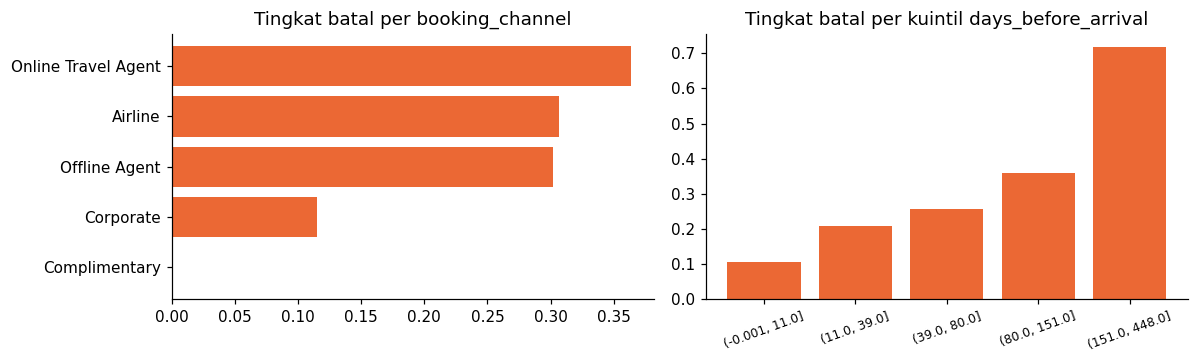

In [7]:
rate = train_df.groupby('booking_channel')[TARGET].agg(['size', 'mean']).sort_values('mean')
lead = train_df.groupby(pd.qcut(train_df['days_before_arrival'], 5), observed=True)[TARGET].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].barh(rate.index, rate['mean'], color=CFG.POS_COLOR)
axes[0].set_title('Tingkat batal per booking_channel')
axes[1].bar(range(len(lead)), lead.values, color=CFG.POS_COLOR)
axes[1].set_xticks(range(len(lead)), [str(i) for i in lead.index], rotation=20, fontsize=8)
axes[1].set_title('Tingkat batal per kuintil days_before_arrival')
plt.tight_layout(); plt.show()

## Verify Data Quality

In [8]:
print('Duplikat penuh (di luar id) di train:', train_df.duplicated(subset=FEATURES + [TARGET]).sum())
print('Baris lengkap di train:', f"{train_df[FEATURES].notna().all(axis=1).mean():.1%}")
print('id unik:', train_df[ID_COL].is_unique and test_df[ID_COL].is_unique,
      '| id train & test beririsan:', bool(set(train_df[ID_COL]) & set(test_df[ID_COL])))

Duplikat penuh (di luar id) di train: 64
Baris lengkap di train: 60.8%
id unik: True | id train & test beririsan: False


#### Insights

> Train memuat 64 duplikat penuh di luar `id` dan hanya 60,8% baris yang lengkap, jadi imputasi wajib (menghapus baris akan membuang 39,2% data dan tidak mungkin dilakukan pada test). Persentase nilai kosong train dan test hampir sama untuk setiap kolom, `id` unik, dan tidak ada `id` yang beririsan.

---

# Training and Validation Split <a name="4"></a>

---

Split dilakukan sebelum data preparation sehingga data validasi tetap tidak terlihat. Hanya train.csv yang di-split.

Duplikat penuh dibuang sebelum split agar baris yang identik tidak muncul di latih dan validasi sekaligus. Split 80/20 bersifat berstrata terhadap target.

In [9]:
train_clean = drop_duplicates(train_df)
y_all = train_clean[TARGET].to_numpy(int)

fit_idx, val_idx = stratified_holdout(y_all, CFG.HOLDOUT, CFG.SEED)
train_set, val_set = train_clean.iloc[fit_idx], train_clean.iloc[val_idx]
y_train, y_val = y_all[fit_idx], y_all[val_idx]

print(f'Duplikat dibuang: {len(train_df) - len(train_clean)}')
print(f'train_set {train_set.shape}  batal {y_train.mean():.2%}')
print(f'val_set   {val_set.shape}  batal {y_val.mean():.2%}')

Duplikat dibuang: 64
train_set (21847, 19)  batal 32.75%
val_set   (5462, 19)  batal 32.75%


---

# Data Preparation <a name="5"></a>

---

Setiap langkah di bawah diimplementasikan di kelas `Preprocessor` (`src/algoritma/lr/preprocessing.py`, pandas + NumPy). Sel-sel di bagian ini menampilkan bukti untuk tiap keputusan, hanya memakai `train_set`. Statistik (median, kategori, mean/std) dipelajari dari data latih lalu diterapkan ke validasi dan test.

## Select Data

Seluruh 17 fitur dipakai. `id` tidak dipakai sebagai fitur. Fitur yang lemah secara univariat (mis. `room_category`) tidak dibuang karena regularisasi dapat mengecilkan bobotnya.

In [10]:
print(len(FEATURES), 'fitur:', FEATURES)

17 fitur: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'prior_cancellations', 'prior_completed_bookings', 'special_requests', 'days_before_arrival', 'nightly_rate_idr', 'needs_parking', 'is_returning_guest', 'arrival_year', 'arrival_month', 'arrival_day', 'meal_package', 'room_category', 'booking_channel']


## Clean Data

### Missing Values

Tingkat batal saat kosong dibandingkan dengan saat terisi untuk tiap kolom.

In [11]:
rows = []
for col in FEATURES:
    miss = train_set[col].isna()
    if miss.any():
        rows.append({'kolom': col, 'n_kosong': int(miss.sum()),
                     'batal_saat_kosong': y_train[miss.to_numpy()].mean(),
                     'batal_saat_terisi': y_train[~miss.to_numpy()].mean()})
pd.DataFrame(rows).set_index('kolom').round(3)

,n_kosong,batal_saat_kosong,batal_saat_terisi
kolom,,,
num_adults,651,0.323,0.328
num_children,2446,0.334,0.327
special_requests,2037,0.403,0.320
days_before_arrival,875,0.311,0.328
nightly_rate_idr,1560,0.303,0.329
needs_parking,851,0.303,0.328
meal_package,1381,0.326,0.328
room_category,788,0.339,0.327


#### Insights

> Hanya `special_requests` yang tingkat batalnya berbeda jelas saat kosong (40,3% terhadap 32,0%), sehingga kolom ini diimputasi 0 (nilai yang paling mungkin menurut hasil eda) dan diberi penanda `special_requests_missing`. Kolom numerik lain diimputasi median train. `nightly_rate_idr` diimputasi median per `booking_channel`, karena median kanal Complimentary adalah 0 sedangkan median global sekitar 1,6 juta. Nilai kosong kategorikal menjadi kategori `kosong`.

### Duplicates

In [12]:
print('Duplikat dibuang dari train:', len(train_df) - len(train_clean))
print('Duplikat di test (tidak disentuh):', test_df.duplicated(subset=FEATURES).sum())

Duplikat dibuang dari train: 64
Duplikat di test (tidak disentuh): 3


#### Insights

> 64 duplikat dibuang dari train sebelum split, agar baris identik tidak berada di latih dan validasi sekaligus. Test tidak disentuh (3 baris duplikat tetap ada), karena setiap baris test harus diprediksi.

### Outliers

In [13]:
rate = train_set['nightly_rate_idr']
print(f'nightly_rate_idr (tidak dipangkas): maks train_set {rate.max():,.0f}, '
      f'> 6 juta {int((rate > 6_000_000).sum())} baris, persentil 99,9 {rate.quantile(0.999):,.0f}, '
      f'maks test {test_df["nightly_rate_idr"].max():,.0f}')
print('Maks prior_cancellations:', train_set['prior_cancellations'].max(),
      '| maks prior_completed_bookings:', train_set['prior_completed_bookings'].max(),
      '| skew:', train_set[['prior_cancellations', 'prior_completed_bookings']].skew().round(1).tolist())

nightly_rate_idr (tidak dipangkas): maks train_set 9,165,000, > 6 juta 3 baris, persentil 99,9 4,511,706, maks test 5,700,000
Maks prior_cancellations: 13 | maks prior_completed_bookings: 58 | skew: [25.5, 19.2]


#### Insights

> Tidak ada nilai yang dipangkas. `nightly_rate_idr` di atas 6 juta (3 baris di `train_set`, maks 9,17 juta) tetap masuk akal secara domain (mis. kamar suite atau kamar keluarga), dan test tidak memiliki nilai di atas 5,7 juta. Uji stratified 5-fold CV menunjukkan pemangkasan pada 6 juta maupun winsorizing pada persentil 99,9 tidak mengubah Macro F1 (0,7744 sampai 0,7749) maupun bobot fitur harga, karena 3 baris dari sekitar 25 ribu terlalu sedikit untuk memengaruhi model, sehingga nilai asli dipertahankan. Nilai aneh lain juga dipertahankan karena informatif menurut `eda.ipynb` (mis. tarif 0 hampir tidak pernah batal). `prior_cancellations` dan `prior_completed_bookings` sangat miring (skew 25,5 dan 19,2), sehingga ditransformasi `log1p` sebelum standardisasi agar beberapa nilai besar tidak mendominasi gradien. Nilai `num_children` yang ekstrem tidak dianggap outlier, melainkan data tidak valid (lihat Data Errors).

### Data Errors

In [14]:
dates = pd.to_datetime({'year': train_set['arrival_year'], 'month': train_set['arrival_month'],
                        'day': train_set['arrival_day']}, errors='coerce')
num = COUNT_COLS + CONT_COLS
print('Tanggal tidak valid:', int(dates.isna().sum()))
print('Nilai negatif:', int((train_set[num] < 0).sum().sum()))
no_adult = train_set['num_adults'].eq(0)
print('num_adults = 0:', int(no_adult.sum()), '| di antaranya punya anak:',
      int((no_adult & train_set['num_children'].gt(0)).sum()))
print('Label kategori:', {c: sorted(train_set[c].dropna().unique()) for c in CAT_COLS})
print('Distribusi num_children:', train_set['num_children'].value_counts().sort_index().to_dict(),
      '| maks test:', test_df['num_children'].max())
for col, upper in Preprocessor().invalid_upper.items():
    bad = train_set[col] > upper
    print(f'{col} > {upper} (tidak valid -> NaN): train_set {int(bad.sum())} baris, '
          f'test {int((test_df[col] > upper).sum())} baris')
    display(train_set.loc[bad, ['num_adults', col, 'room_category', 'nightly_rate_idr', 'booking_channel']])

Tanggal tidak valid: 0
Nilai negatif: 0
num_adults = 0: 88 | di antaranya punya anak: 87
Label kategori: {'meal_package': ['Breakfast', 'Full Board', 'Half Board', 'Room Only'], 'room_category': ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G'], 'booking_channel': ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']}
Distribusi num_children: {0.0: 17776, 1.0: 962, 2.0: 646, 3.0: 14, 9.0: 2, 10.0: 1} | maks test: 3.0
num_children > 3 (tidak valid -> NaN): train_set 3 baris, test 0 baris


,num_adults,num_children,room_category,nightly_rate_idr,booking_channel
9086,2.0,10.0,Type G,1413000.0,Online Travel Agent
9206,2.0,9.0,Type D,1231000.0,Online Travel Agent
24697,1.0,9.0,Type B,1578000.0,Corporate


#### Insights

> Tidak ada tanggal tidak valid, nilai negatif, atau label kategori yang tidak konsisten. `num_adults = 0` (88 baris) bukan kesalahan: 87 baris memiliki anak dan satu sisanya `num_children` kosong, sehingga baris tersebut dipertahankan.
>
> `num_children` bernilai 0 sampai 3, lalu langsung melompat ke 9 dan 10 (3 baris di `train_set`, tidak ada di test). Ketiga pesanan itu hanya berisi 1 sampai 2 dewasa di kamar biasa dengan harga wajar, sehingga hampir pasti salah input, bukan keluarga besar. Nilai `num_children > 3` karena itu dianggap **tidak valid**: diubah menjadi NaN lalu diimputasi median (0) seperti missing value lainnya. Pemangkasan (clip) tidak dipakai karena nilai aslinya tidak diketahui, sehingga tidak ada alasan menganggap pesanan tersebut memiliki jumlah anak terbanyak.

## Construct Data

### Attribute Construction

In [15]:
base = Preprocessor()._base(train_set)
for col in ['special_requests_missing', 'rate_is_zero']:
    print(f'{col:<26}', base.groupby(col)[col].size().to_dict(), '| tingkat batal:',
          pd.Series(y_train).groupby(base[col].to_numpy()).mean().round(3).to_dict())
print('arrival_ym unik:', base['arrival_ym'].nunique(), '| booking_ym unik:', base['booking_ym'].nunique())

special_requests_missing   {0.0: 19810, 1.0: 2037} | tingkat batal: {0.0: 0.32, 1.0: 0.403}
rate_is_zero               {0.0: 21518, 1.0: 329} | tingkat batal: {0.0: 0.332, 1.0: 0.003}
arrival_ym unik: 18 | booking_ym unik: 26


#### Insights

> `rate_is_zero` memisahkan 329 pesanan complimentary dengan tingkat batal 0,3% (terhadap 33,2%), dan `special_requests_missing` menyimpan sinyal kekosongan. `arrival_ym` (18 kategori) dan `booking_ym` (26 kategori, dari tanggal kedatangan dikurangi lead time) menangkap efek periode yang tidak naik-turun secara linear terhadap bulan, sesuatu yang tidak bisa ditangkap model linear dari `arrival_month` mentah. `lead_log = log1p(days_before_arrival)` ditambahkan karena hubungan lead time dengan pembatalan melandai pada lead time panjang.

In [16]:
lead_labels = ['0-7', '8-30', '31-90', '91-180', '>180']
lead_bin = pd.cut(train_set['days_before_arrival'], LEAD_BINS, labels=lead_labels)
by_chan = train_set.assign(lead=lead_bin).groupby(['booking_channel', 'lead'], observed=True)[TARGET]
print('Tingkat batal per kanal x rentang lead time (train_set):')
display(by_chan.mean().unstack().round(3))
print('Jumlah baris:')
display(by_chan.size().unstack())
print(f'{len(Preprocessor().fit(train_set).inter_cols)} kolom interaksi, contoh:',
      Preprocessor().fit(train_set).inter_cols[:4])

Tingkat batal per kanal x rentang lead time (train_set):


lead,0-7,8-30,31-90,91-180,>180
booking_channel,,,,,
Airline,0.222,0.389,NaN,NaN,NaN
Complimentary,0.000,0.000,0.000,0.000,0.000
Corporate,0.083,0.084,0.180,0.438,0.800
Offline Agent,0.077,0.023,0.085,0.355,0.671
Online Travel Agent,0.112,0.234,0.334,0.496,0.809


Jumlah baris:


lead,0-7,8-30,31-90,91-180,>180
booking_channel,,,,,
Airline,54.0,18.0,NaN,NaN,NaN
Complimentary,157.0,47.0,16.0,5.0,2.0
Corporate,556.0,379.0,150.0,64.0,10.0
Offline Agent,469.0,710.0,1772.0,1475.0,1654.0
Online Travel Agent,2028.0,2776.0,4357.0,2873.0,1400.0


20 kolom interaksi, contoh: ['lead_bin1_x_Airline', 'lead_bin2_x_Airline', 'lead_bin3_x_Airline', 'lead_bin4_x_Airline']


#### Insights

> Kenaikan tingkat batal terhadap lead time berbeda tajam antarkanal. Pada lead time 8 sampai 30 hari, Online Travel Agent batal 23,4%, sedangkan Offline Agent hanya 2,3%. Pada 31 sampai 90 hari, perbandingannya 33,4% terhadap 8,5%. Corporate hampir tidak batal di bawah 30 hari (8%) tetapi naik ke 80% di atas 180 hari. Satu fitur `lead_log` memaksa kemiringan yang sama untuk semua kanal, sehingga model linear salah di ujung-ujung lead time (lihat Error Analysis).
>
> Karena itu ditambahkan **20 fitur interaksi** `lead_bin{k}_x_{kanal}`: indikator kanal dikali indikator rentang lead time (0-7, 8-30, 31-90, 91-180, >180 hari, dengan 0-7 sebagai acuan). Ini adalah *basis expansion* berupa fungsi tangga ditambah interaksi [31, Sec. 5.1], sehingga setiap kanal mendapat kurva bertingkatnya sendiri tetapi model tetap linear dalam parameter. Uji stratified 5-fold CV (l1, λ = 10⁻⁴, IRLS-CD) menaikkan Macro F1 OOF dari 0,7766 ke 0,7822 dan ROC-AUC dari 0,8706 ke 0,8737. Pada tiga pembagian fold lain (seed 1, 7, 2024) kenaikannya +0,006 sampai +0,008 dan menang di 15 dari 15 fold, sehingga perbaikannya konsisten. Kandidat lain yang diuji tidak membantu dan tidak dipakai: bin lead time tanpa interaksi (+0,003, sudah tercakup interaksi), interaksi kanal × `lead_log` linear (−0,001), harga relatif terhadap median per `room_category` (0,000), dan hari kedatangan dalam minggu (−0,001).

### Feature Scaling

In [17]:
raw_std = train_set[['days_before_arrival', 'nightly_rate_idr', 'num_adults', 'special_requests']].std()
print('Simpangan baku sebelum standardisasi:')
print(raw_std.round(2).to_string())

Simpangan baku sebelum standardisasi:
days_before_arrival        85.99
nightly_rate_idr       590565.93
num_adults                  0.52
special_requests            0.79


#### Insights

> Rentang fitur sangat timpang, dengan simpangan baku dari 0,52 (`num_adults`) hingga sekitar 590 ribu (`nightly_rate_idr`). Tanpa standardisasi, gradient descent didominasi fitur berskala besar dan penalti regularisasi tidak adil antarfitur. Seluruh 17 kolom numerik dan 20 kolom interaksi distandardisasi (z-score) dengan mean dan simpangan baku `train_set`.

### Encoding

In [18]:
p = Preprocessor().fit(train_set)
for col in p.cat_cols:
    print(f'{col:<16} {len(p.levels_[col]):>3} kolom one-hot  ', p.levels_[col][:8],
          '...' if len(p.levels_[col]) > 8 else '')

meal_package       5 kolom one-hot   ['Breakfast', 'Half Board', 'Room Only', 'kosong', 'lainnya'] 
room_category      8 kolom one-hot   ['Type A', 'Type B', 'Type C', 'Type D', 'Type F', 'Type G', 'kosong', 'lainnya'] 
booking_channel    5 kolom one-hot   ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent'] 
arrival_ym        18 kolom one-hot   ['2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02'] ...
booking_ym        27 kolom one-hot   ['2022-10', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07'] ...


#### Insights

> Fitur kategorikal di-one-hot. Kategori dengan frekuensi di bawah 30 digabung menjadi `lainnya` (Full Board 4 baris, Type E 7 baris) agar tidak menghasilkan kolom yang hampir selalu nol, dan kategori yang tidak dikenal di test juga dipetakan ke `lainnya`. Hasilnya 63 kolom one-hot, sehingga bersama 17 kolom numerik dan 20 kolom interaksi totalnya 100 kolom.

### Dimensionality Reduction

Reduksi dimensi tidak diterapkan. Matriks akhir hanya 100 kolom, kecil untuk logistic regression, dan pada eda.ipynb proyeksi PCA 2D hanya menyimpan 25,7% variansi dengan ROC-AUC 0,693, jauh di bawah fitur penuh. Pengurangan kompleksitas di regularisasi L1/Elastic Net.

## Class Balance

In [19]:
print(pd.Series(y_train).value_counts(normalize=True).rename({0: 'tidak batal', 1: 'batal'}).round(4))

tidak batal    0.6725
batal          0.3275
Name: proportion, dtype: float64


#### Insights

> Kelas batal 32,75%, tidak seimbang tetapi tidak ekstrem. Tidak dilakukan resampling. Ketidakseimbangan ditangani dengan memilih threshold keputusan yang memaksimumkan Macro F1.

## Format Data

Keluaran `Preprocessor.transform` adalah matriks NumPy `float64` tanpa nilai kosong, dengan nama kolom di `feature_names_`.

---

# Preparation Pipeline <a name="6"></a>

---

Pipeline menggabungkan seluruh langkah dalam urutan yang konsisten: nilai tidak valid → NaN → penanda → imputasi → fitur turunan → kategori kosong/langka → interaksi kanal × lead time → one-hot → standardisasi. `fit` hanya pada `train_set`; `val_set` dan `test` hanya di-`transform`.

In [20]:
prep = Preprocessor().fit(train_set)
X_train, X_val = prep.transform(train_set), prep.transform(val_set)

print('X_train', X_train.shape, '| X_val', X_val.shape)
print('NaN:', int(np.isnan(X_train).sum() + np.isnan(X_val).sum()))
print('mean/std kolom numerik + interaksi X_train:', X_train[:, :len(prep.scaled_cols)].mean().round(6),
      X_train[:, :len(prep.scaled_cols)].std().round(4))

X_train (21847, 100) | X_val (5462, 100)
NaN: 0
mean/std kolom numerik + interaksi X_train: 0.0 0.9726


---

# Modeling and Validation <a name="7"></a>

---

Target adalah `is_canceled`. Model diimplementasikan from scratch dengan NumPy.

## Logistic Regression

Fungsi biaya yang diminimumkan (`lr.py`):

$$J(w,b) = -\frac{1}{n}\sum_{i=1}^{n}\big[y_i \log p_i + (1-y_i)\log(1-p_i)\big] + \lambda\,\Omega(w), \qquad p_i = \sigma(w\cdot x_i + b)$$

| penalty | $\Omega(w)$ |
|---|---|
| `l2` | $\tfrac12\lVert w\rVert_2^2$ |
| `l1` | $\lVert w\rVert_1$ (subgradien $\operatorname{sign}(w)$) |
| `elasticnet` | $\rho\lVert w\rVert_1 + \tfrac{1-\rho}{2}\lVert w\rVert_2^2$ |

Update mini-batch: $w \leftarrow w - \eta\big(\tfrac{1}{|B|}\sum_{i\in B}(p_i - y_i)x_i + \lambda\nabla\Omega(w)\big)$, setara dengan gradient ascent pada log conditional likelihood di [16]. Bias tidak diregularisasi.

In [21]:
print('Hyperparameter optimasi:', TRAIN_KW)

variants = {name_of(c): c for c in [
    dict(penalty=None, lam=0.0, rho=0.5),
    dict(penalty='l2', lam=1e-3, rho=0.5),
    dict(penalty='l1', lam=1e-3, rho=0.5),
    dict(penalty='elasticnet', lam=1e-3, rho=0.5),
]}
models, rows = {}, []
for name, cfg in variants.items():
    start = time.perf_counter()
    models[name] = LogisticRegression(**cfg, **TRAIN_KW).fit(X_train, y_train)
    proba = models[name].predict_proba(X_val)
    rows.append({'model': name, **report(y_val, proba, 0.5),
                 'epochs': len(models[name].loss_history),
                 'near_zero_w': int(np.sum(np.abs(models[name].w) < 1e-2)),
                 'sec': round(time.perf_counter() - start, 2)})
pd.DataFrame(rows).set_index('model').round(4)

Hyperparameter optimasi: {'lr': 0.1, 'n_epochs': 100, 'batch_size': 128, 'tol': 1e-07, 'seed': 42}


,macro_f1,accuracy,f1_cancel,roc_auc,tn,fp,fn,tp,epochs,near_zero_w,sec
model,,,,,,,,,,,
none,0.7739,0.8076,0.6865,0.8728,3260,413,638,1151,100,7,1.92
l2(lam=0.001),0.7712,0.8054,0.6828,0.8714,3255,418,645,1144,100,5,1.88
l1(lam=0.001),0.7717,0.8061,0.6830,0.8693,3262,411,648,1141,100,42,1.88
"elasticnet(lam=0.001,rho=0.5)",0.7684,0.8036,0.6783,0.8702,3258,415,658,1131,100,31,1.89


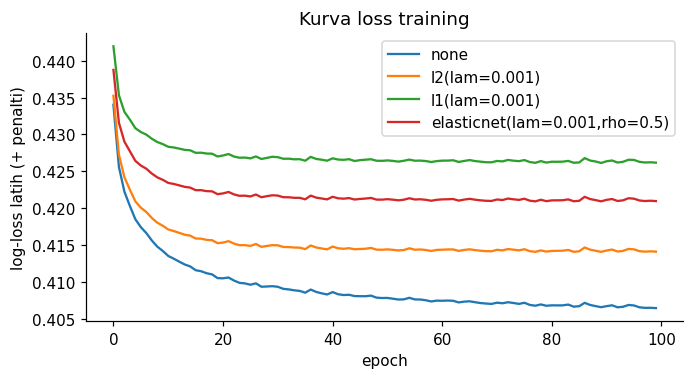

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for name, m in models.items():
    ax.plot(m.loss_history, label=name)
ax.set_xlabel('epoch'); ax.set_ylabel('log-loss latih (+ penalti)')
ax.set_title('Kurva loss training'); ax.legend(); plt.show()

#### Insights

> Dengan solver SGD dan λ = 10⁻³, keempat varian hampir setara di `val_set` (Macro F1 0,768 sampai 0,774 dan ROC-AUC 0,869 sampai 0,873 pada threshold 0,5). L1 menghasilkan bobot paling jarang (42 dari 100 bobot |w| < 0,01), diikuti Elastic Net (31), tanpa penalti (7), dan L2 (5). Karena L1 memakai subgradien, bobot hanya mendekati nol dan tidak tepat nol (bobot tepat nol dibahas di bagian Algoritma Optimasi). Kurva loss sudah melandai sebelum epoch ke-100.

### Tuning Regularisasi (Stratified 5-Fold CV)

Seluruh kandidat `GRID` divalidasi silang pada train (setelah duplikat dibuang). Pada setiap fold, `Preprocessor` di-fit hanya pada bagian latih fold tersebut. Probabilitas out-of-fold dipakai untuk memilih konfigurasi dan threshold dengan Macro F1 tertinggi.

In [23]:
cv = cross_validate(train_clean, y_all)
best_row = cv.sort_values('macro_f1@thr', ascending=False).iloc[0]
best_cfg, threshold = cfg_from_row(best_row), float(best_row['threshold'])
print(f"\nTerbaik: {best_row['config']}  threshold={threshold:.2f}  Macro F1 OOF={best_row['macro_f1@thr']:.4f}")
cv.drop(columns=['penalty', 'lam', 'rho']).set_index('config').round(4)

  none [sgd]                               macroF1@0.5=0.7771  macroF1@0.44=0.7813  AUC=0.8727  epochs~100  (8.5s)
  l2(lam=0.0001) [sgd]                     macroF1@0.5=0.7769  macroF1@0.45=0.7814  AUC=0.8726  epochs~100  (7.8s)
  l2(lam=0.001) [sgd]                      macroF1@0.5=0.7754  macroF1@0.47=0.7803  AUC=0.8714  epochs~100  (8.1s)
  l2(lam=0.01) [sgd]                       macroF1@0.5=0.7687  macroF1@0.44=0.7760  AUC=0.8654  epochs~100  (7.6s)
  l1(lam=0.0001) [sgd]                     macroF1@0.5=0.7769  macroF1@0.45=0.7810  AUC=0.8724  epochs~100  (7.6s)
  l1(lam=0.001) [sgd]                      macroF1@0.5=0.7754  macroF1@0.44=0.7803  AUC=0.8692  epochs~100  (7.5s)
  elasticnet(lam=0.0001,rho=0.5) [sgd]     macroF1@0.5=0.7770  macroF1@0.45=0.7813  AUC=0.8725  epochs~100  (8.1s)
  elasticnet(lam=0.001,rho=0.5) [sgd]      macroF1@0.5=0.7752  macroF1@0.45=0.7800  AUC=0.8702  epochs~100  (8.1s)
  none [irls_cd]                           macroF1@0.5=0.7786  macroF1@0.46=0.78

,solver,macro_f1@0.5,threshold,macro_f1@thr,accuracy@thr,roc_auc,epochs_mean,sec
config,,,,,,,,
none [sgd],sgd,0.7771,0.44,0.7813,0.8071,0.8727,100.0,8.5413
l2(lam=0.0001) [sgd],sgd,0.7769,0.45,0.7814,0.8082,0.8726,100.0,7.7606
l2(lam=0.001) [sgd],sgd,0.7754,0.47,0.7803,0.8095,0.8714,100.0,8.0938
l2(lam=0.01) [sgd],sgd,0.7687,0.44,0.7760,0.8039,0.8654,100.0,7.6196
l1(lam=0.0001) [sgd],sgd,0.7769,0.45,0.7810,0.8078,0.8724,100.0,7.5789
l1(lam=0.001) [sgd],sgd,0.7754,0.44,0.7803,0.8065,0.8692,100.0,7.5400
"elasticnet(lam=0.0001,rho=0.5) [sgd]",sgd,0.7770,0.45,0.7813,0.8081,0.8725,100.0,8.1384
"elasticnet(lam=0.001,rho=0.5) [sgd]",sgd,0.7752,0.45,0.7800,0.8071,0.8702,100.0,8.1474
none [irls_cd],irls_cd,0.7786,0.46,0.7824,0.8094,0.8739,12.6,13.4633


#### Insights

> Seluruh 16 konfigurasi berada dalam selisih 0,007 Macro F1 (0,7753 sampai 0,7824). Penalti yang lebih kuat justru menurunkan skor (L2 λ = 10⁻²: 0,7753 dengan IRLS-CD dan 0,7760 dengan SGD), sedangkan tanpa penalti, L1, L2, dan Elastic Net dengan λ = 10⁻⁴ praktis setara (0,7810 sampai 0,7824). Artinya model dengan 100 fitur untuk sekitar 27 ribu baris tidak overfitting, sehingga regularisasi tidak banyak membantu di data ini. Konfigurasi terbaik adalah **tanpa penalti dengan solver IRLS-CD dan threshold 0,46** (Macro F1 OOF 0,7824, ROC-AUC 0,8739), hanya 0,0002 di atas L1 λ = 10⁻⁴. Pada penalti lemah (tanpa penalti dan λ = 10⁻⁴), IRLS-CD selalu lebih tinggi daripada SGD, dan terbaiknya 0,7824 terhadap 0,7814 (lihat bagian Algoritma Optimasi). Threshold optimal konsisten di 0,44 sampai 0,47, di bawah 0,5, sehingga sedikit lebih mudah memprediksi batal menguntungkan Macro F1.

## Model Evaluation

Konfigurasi terbaik dilatih ulang pada `train_set` dan dievaluasi pada `val_set`.

,macro_f1,accuracy,f1_cancel,roc_auc,tn,fp,fn,tp
threshold 0.5,0.7731,0.8067,0.6857,0.8735,3254.0,419.0,637.0,1152.0
threshold 0.46,0.7830,0.8100,0.7066,0.8735,3174.0,499.0,539.0,1250.0


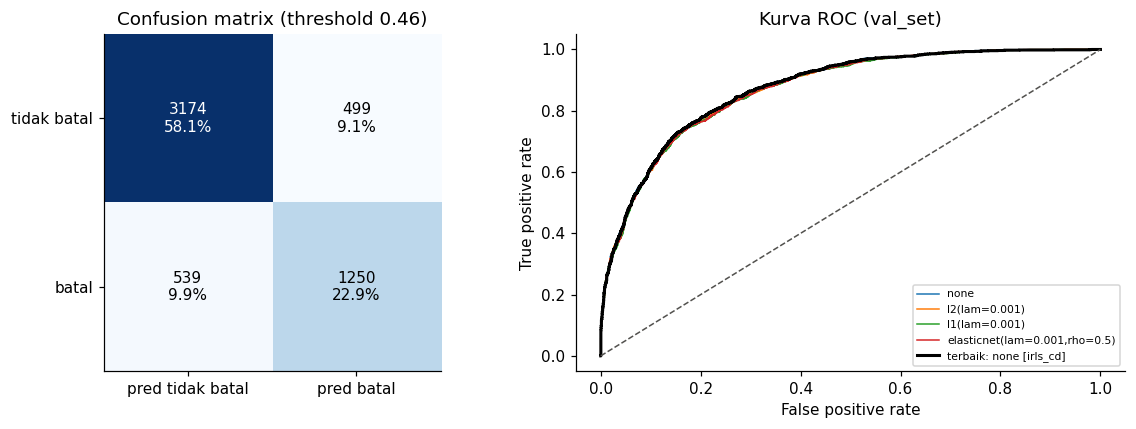

In [24]:
best_model = LogisticRegression(**best_cfg, **TRAIN_KW).fit(X_train, y_train)
p_val = best_model.predict_proba(X_val)
display(pd.DataFrame({'threshold 0.5': report(y_val, p_val, 0.5),
                      f'threshold {threshold:.2f}': report(y_val, p_val, threshold)}).T.round(4))


def roc_points(y, score):
    order = np.argsort(-score)
    tp, fp = np.cumsum(y[order] == 1), np.cumsum(y[order] == 0)
    return np.r_[0, fp / fp[-1]], np.r_[0, tp / tp[-1]]


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
r = report(y_val, p_val, threshold)
cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]])
axes[0].imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, f'{v}\n{v / cm.sum():.1%}', ha='center', va='center',
                 color='white' if v > cm.max() / 2 else 'black')
axes[0].set_xticks([0, 1], ['pred tidak batal', 'pred batal'])
axes[0].set_yticks([0, 1], ['tidak batal', 'batal'])
axes[0].set_title(f'Confusion matrix (threshold {threshold:.2f})')
for name, m in models.items():
    fpr, tpr = roc_points(y_val, m.predict_proba(X_val))
    axes[1].plot(fpr, tpr, linewidth=1, label=name)
fpr, tpr = roc_points(y_val, p_val)
axes[1].plot(fpr, tpr, color='black', linewidth=2, label=f"terbaik: {name_of(best_cfg)}")
axes[1].plot([0, 1], [0, 1], color=CFG.MUTED, linestyle='--', linewidth=1)
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate')
axes[1].set_title('Kurva ROC (val_set)'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

#### Insights

> Pada `val_set`, threshold 0,46 menaikkan Macro F1 dari 0,7731 ke 0,7830, hampir sama dengan Macro F1 OOF (0,7824), sehingga estimasi CV dapat dipercaya. Threshold ini menukar FN (637 → 539) dengan FP (419 → 499). ROC-AUC 0,8735 tidak bergantung pada threshold. Kurva ROC keempat varian SGD dan model terbaik hampir berimpit, sesuai hasil CV.

## Improvements (Optional)

Threshold keputusan bawaan 0,5 tidak dioptimalkan untuk Macro F1. Kurva berikut memperlihatkan Macro F1 `val_set` terhadap threshold; threshold final tetap dipilih dari prediksi out-of-fold CV, bukan dari `val_set`.

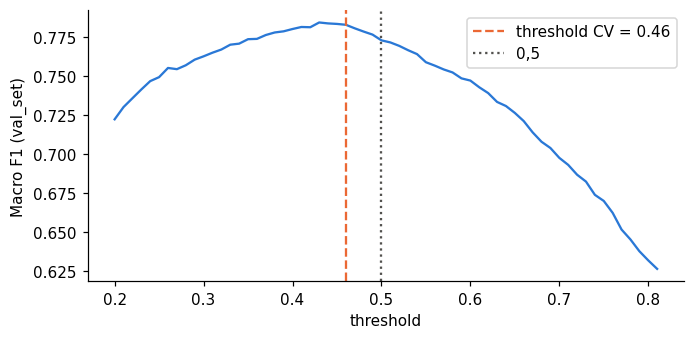

In [25]:
scores = [macro_f1(y_val, (p_val >= t).astype(int)) for t in THRESHOLDS]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(THRESHOLDS, scores, color=CFG.NEG_COLOR)
ax.axvline(threshold, color=CFG.POS_COLOR, linestyle='--', label=f'threshold CV = {threshold:.2f}')
ax.axvline(0.5, color=CFG.MUTED, linestyle=':', label='0,5')
ax.set_xlabel('threshold'); ax.set_ylabel('Macro F1 (val_set)'); ax.legend(); plt.show()

#### Insights

> Macro F1 `val_set` membentuk dataran landai di threshold 0,43 sampai 0,46 (0,7830 sampai 0,7845), dan threshold hasil CV (0,46) berada di dalamnya, sehingga pilihan ini stabil. Selisihnya dengan puncak `val_set` (0,43) hanya 0,0015, dan threshold tidak disetel ulang pada `val_set` agar tidak overfit ke split tersebut. Kenaikan terbesar justru datang dari fitur interaksi kanal × lead time (+0,006 Macro F1 OOF, bagian Attribute Construction), lebih besar daripada efek regularisasi maupun pemilihan solver, sehingga perbaikan berikutnya juga lebih mungkin datang dari fitur.

---

# Comparison with scikit-learn <a name="8"></a>

---

`sklearn.linear_model.LogisticRegression` diberi tujuan optimasi yang setara. `lr.py` memakai rata-rata log-loss ditambah $\lambda\,\Omega(w)$, sedangkan scikit-learn memakai $C\sum \text{log-loss} + \Omega(w)$, sehingga $C = 1/(n\lambda)$, dengan `l1_ratio` $= \rho$. Satu konfigurasi terbaik per jenis penalti dari CV dibandingkan pada split yang sama (threshold 0,5).

In [26]:
per_penalty = (cv.assign(p=cv['penalty'].fillna('none'))
               .sort_values('macro_f1@thr', ascending=False).groupby('p').head(1))
cmp = compare_sklearn(train_clean, y_all, [cfg_from_row(r) for _, r in per_penalty.iterrows()])
cmp.to_csv(CFG.OUTPUT_DIR / 'lr_sklearn_comparison.csv', index=False)
cmp.set_index(['config', 'impl']).round(4)

  none [irls_cd]                           label sama 100.00%  max|w_scratch - w_sklearn|=5.8479  nonzero w: scratch=98 sklearn=98
  l1(lam=0.0001) [irls_cd]                 label sama 99.98%  max|w_scratch - w_sklearn|=0.1000  nonzero w: scratch=84 sklearn=86
  elasticnet(lam=0.0001,rho=0.5) [irls_cd] label sama 100.00%  max|w_scratch - w_sklearn|=0.0615  nonzero w: scratch=87 sklearn=88
  l2(lam=0.0001) [irls_cd]                 label sama 100.00%  max|w_scratch - w_sklearn|=0.0028  nonzero w: scratch=98 sklearn=98


macro_f1  accuracy  f1_cancel  roc_auc    tn   fp   fn    tp   waktu_s  bobot_nol
config                                   impl                                                                                      
none [irls_cd]                           scratch    0.7731    0.8067     0.6857   0.8735  3254  419  637  1152    3.0264          2
                                         sklearn    0.7731    0.8067     0.6857   0.8736  3254  419  637  1152   20.6819          2
l1(lam=0.0001) [irls_cd]                 scratch    0.7739    0.8072     0.6871   0.8741  3253  420  633  1156    3.8964         16
                                         sklearn    0.7736    0.8070     0.6867   0.8741  3253  420  634  1155  167.0568         14
elasticnet(lam=0.0001,rho=0.5) [irls_cd] scratch    0.7722    0.8059     0.6845   0.8740  3252  421  639  1150    4.7823         13
                                         sklearn    0.7722    0.8059     0.6845   0.8740  3252  421  639  1150  182.9704         12
l2(lam=0.0001) [irls_cd]                 scratch    0.7720    0.8057     0.6843   0.8739  3251  422  639  1150    5.3085          2
                                         sklearn    0.7720    0.8057     0.6843   0.8739  3251  422  639  1150    1.2726          2

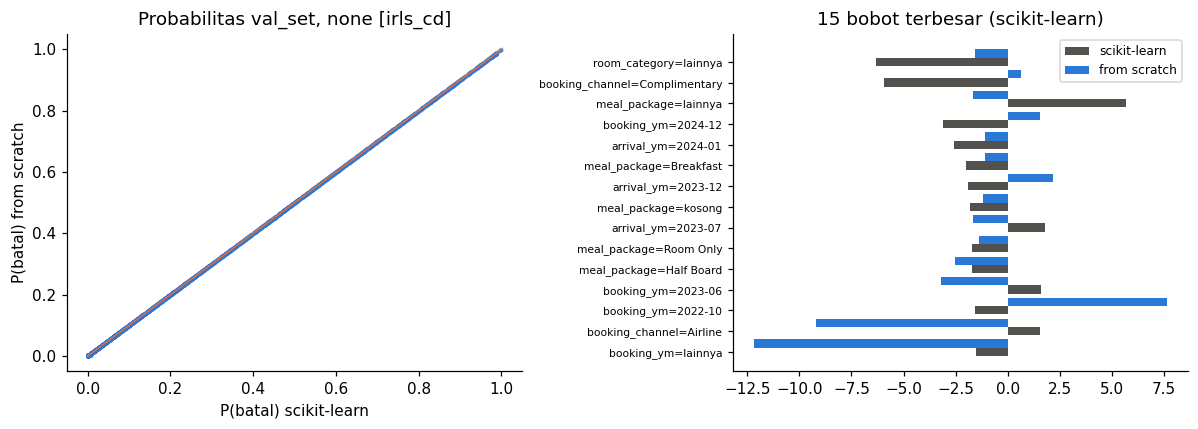

Korelasi probabilitas: 1.0000  |  label sama @0.5: 100.00%


In [27]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sk = sklearn_model(best_cfg, len(y_train)).fit(X_train, y_train)
p_sk = sk.predict_proba(X_val)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(p_sk, p_val, s=3, alpha=0.3, color=CFG.NEG_COLOR)
axes[0].plot([0, 1], [0, 1], color=CFG.POS_COLOR, linewidth=1)
axes[0].set_xlabel('P(batal) scikit-learn'); axes[0].set_ylabel('P(batal) from scratch')
axes[0].set_title(f'Probabilitas val_set, {name_of(best_cfg)}')
idx = np.argsort(-np.abs(sk.coef_.ravel()))[:15]
axes[1].barh(np.array(prep.feature_names_)[idx][::-1], sk.coef_.ravel()[idx][::-1],
             height=0.4, label='scikit-learn', color=CFG.MUTED)
axes[1].barh(np.arange(15)[::-1] + 0.4, best_model.w[idx][::-1],
             height=0.4, label='from scratch', color=CFG.NEG_COLOR)
axes[1].tick_params(axis='y', labelsize=7); axes[1].legend(fontsize=8)
axes[1].set_title('15 bobot terbesar (scikit-learn)')
plt.tight_layout(); plt.show()
print(f'Korelasi probabilitas: {np.corrcoef(p_sk, p_val)[0, 1]:.4f}  |  '
      f'label sama @0.5: {np.mean((p_sk >= 0.5) == (p_val >= 0.5)):.2%}')

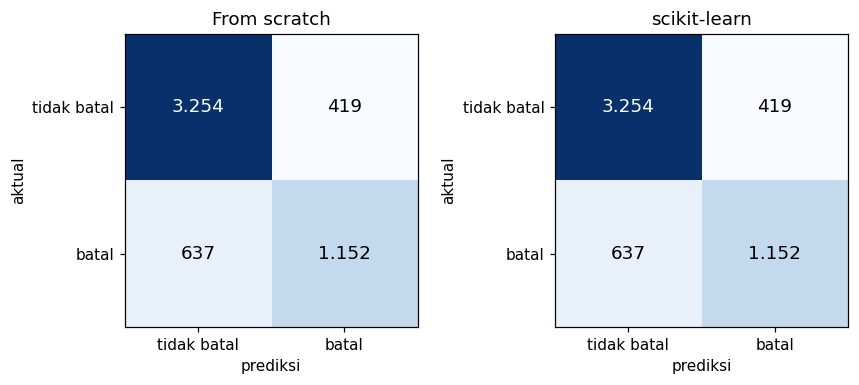

In [28]:
# Confusion matrix konfigurasi terbaik pada val_set (threshold 0.5), dari tabel perbandingan di atas
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, impl, title in [(axes[0], 'scratch', 'From scratch'), (axes[1], 'sklearn', 'scikit-learn')]:
    r = cmp[(cmp['config'] == name_of(best_cfg)) & (cmp['impl'] == impl)].iloc[0]
    cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]], dtype=int)
    ax.imshow(cm, cmap='Blues')
    for a in range(2):
        for b in range(2):
            ax.text(b, a, f'{cm[a, b]:,}'.replace(',', '.'), ha='center', va='center', fontsize=12,
                    color='white' if cm[a, b] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['tidak batal', 'batal']); ax.set_yticks([0, 1], ['tidak batal', 'batal'])
    ax.set_xlabel('prediksi'); ax.set_ylabel('aktual'); ax.set_title(title)
    for s in ax.spines.values():
        s.set_visible(True)
plt.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'lr_confusion_matrix.png', dpi=150, bbox_inches='tight'); plt.show()

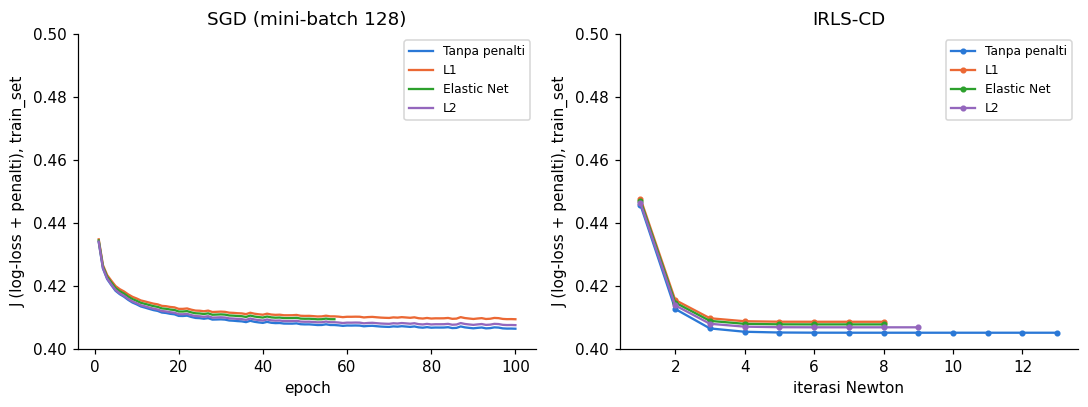

In [29]:
# Kurva loss (J = log-loss + penalti, train_set) tiap penalti, untuk kedua solver
PEN_LABEL = {None: 'Tanpa penalti', 'l1': 'L1', 'elasticnet': 'Elastic Net', 'l2': 'L2'}
pen_cfgs = sorted([cfg_from_row(r) for _, r in per_penalty.iterrows()],
                  key=lambda c: list(PEN_LABEL).index(c['penalty']))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for c, color in zip(pen_cfgs, ['#2a78d6', '#eb6834', '#2ca02c', '#9467bd']):
    for ax, solver, mark in [(axes[0], 'sgd', ''), (axes[1], 'irls_cd', 'o')]:
        m = LogisticRegression(**dict(c, solver=solver), **TRAIN_KW).fit(X_train, y_train)
        ax.plot(np.arange(1, len(m.loss_history) + 1), m.loss_history, marker=mark, markersize=3,
                color=color, label=PEN_LABEL[c['penalty']])
axes[0].set_title('SGD (mini-batch 128)'); axes[0].set_xlabel('epoch')
axes[1].set_title('IRLS-CD'); axes[1].set_xlabel('iterasi Newton')
for ax in axes:
    ax.set_ylabel('J (log-loss + penalti), train_set'); ax.set_ylim(0.40, 0.50); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'lr_loss_curves.png', dpi=150, bbox_inches='tight'); plt.show()

#### Insights

> Implementasi from scratch praktis identik dengan scikit-learn. Untuk keempat penalti (seluruhnya memakai IRLS-CD sesuai hasil CV), label sama 99,98% sampai 100%, selisih Macro F1 paling besar 0,0003, dan korelasi probabilitas model terbaik 1,0000. Ini terjadi karena IRLS-CD konvergen ke optimum yang sama dengan solver scikit-learn. Selisih bobot terbesar ada pada model tanpa penalti (5,85), karena kolom one-hot setiap fitur kategorikal bersama bias saling kolinear, sehingga bobotnya tidak unik walaupun prediksinya identik (label sama 100%). Pada L1, kedua implementasi menghasilkan bobot tepat nol dalam jumlah yang hampir sama (84 dan 86 dari 100 bobot tidak nol).

---

# Saving and Loading Models <a name="9"></a>

---

Model disimpan sebagai berkas `.npz` NumPy (bobot, bias, hyperparameter) tanpa pickle, lalu dimuat ulang dan diperiksa bahwa prediksinya identik.

In [30]:
import tempfile
val_model_path = Path(tempfile.mkdtemp()) / 'lr_model_val.npz'   # hanya demo save/load, tidak disimpan di output/
best_model.save(val_model_path)
restored = LogisticRegression.load(val_model_path)
assert np.array_equal(restored.predict_proba(X_val), p_val)
print(f'{val_model_path} dimuat ulang: prediksi identik ({len(p_val)} baris)')
print({k: getattr(restored, k) for k in ('b', 'lr', 'n_epochs', 'penalty', 'lam', 'rho')})

C:\Users\reva\AppData\Local\Temp\tmpot4j9e6a\lr_model_val.npz dimuat ulang: prediksi identik (5462 baris)
{'b': -5.434242481839467e-12, 'lr': 0.1, 'n_epochs': 100, 'penalty': None, 'lam': 0.0, 'rho': 0.5}


---

# Kaggle Submission <a name="10"></a>

---

Pipeline dan model final di-fit pada seluruh train (setelah duplikat dibuang), sedangkan test hanya di-`transform`. Konfigurasi dan threshold berasal dari CV. Berkas submisi berisi kolom `id` dan `is_canceled`, dan sama persis dengan keluaran `python src/kaggle/lr_submission.py`.

In [31]:
prep_full = Preprocessor().fit(train_clean)
X_full, X_test = prep_full.transform(train_clean), prep_full.transform(test_df)
final_model = LogisticRegression(**best_cfg, **TRAIN_KW).fit(X_full, y_all)

model_path = CFG.OUTPUT_DIR / 'lr_model.npz'
final_model.save(model_path)
p_test = LogisticRegression.load(model_path).predict_proba(X_test)
assert np.array_equal(p_test, final_model.predict_proba(X_test))

submission = pd.DataFrame({ID_COL: test_df[ID_COL], TARGET: (p_test >= threshold).astype(int)})
assert len(submission) == len(test_df) and submission[ID_COL].is_unique
submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
print(f"Model: {name_of(best_cfg)}  threshold={threshold:.2f}")
print(f"Tersimpan: {CFG.OUTPUT_DIR / 'submission.csv'}  ({len(submission)} baris, "
      f"prediksi batal {submission[TARGET].mean():.1%})")
submission.head()

Model: none [irls_cd]  threshold=0.46
Tersimpan: ..\..\output\lr\submission.csv  (6844 baris, prediksi batal 31.5%)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

Kesalahan model terbaik pada `val_set` dipecah per kelompok untuk melihat di mana model linear paling lemah.

In [32]:
pred_val = (p_val >= threshold).astype(int)
err = val_set.assign(y=y_val, pred=pred_val,
                     fp=(pred_val == 1) & (y_val == 0), fn=(pred_val == 0) & (y_val == 1),
                     lead_bin=pd.qcut(val_set['days_before_arrival'], 5,
                                      labels=['Q1 (0-11)', 'Q2 (12-39)', 'Q3 (40-81)', 'Q4 (82-151)',
                                              'Q5 (152+)']).astype(object).fillna('kosong'))


def by(col):
    g = err.groupby(col)
    out = pd.DataFrame({'n': g.size(), 'batal': g['y'].mean(), 'pred_batal': g['pred'].mean(),
                        'FP_rate': g['fp'].mean(), 'FN_rate': g['fn'].mean()})
    out['macro_f1'] = [macro_f1(d['y'].to_numpy(), d['pred'].to_numpy()) for _, d in g]
    return out.round(3)


display(by('booking_channel'))
display(by('lead_bin'))

,n,batal,pred_batal,FP_rate,FN_rate,macro_f1
booking_channel,,,,,,
Airline,14,0.429,0.214,0.071,0.286,0.591
Complimentary,62,0.000,0.000,0.000,0.000,0.500
Corporate,303,0.089,0.040,0.010,0.059,0.712
Offline Agent,1569,0.295,0.282,0.084,0.098,0.779
Online Travel Agent,3514,0.368,0.368,0.103,0.104,0.778


,n,batal,pred_batal,FP_rate,FN_rate,macro_f1
lead_bin,,,,,,
Q1 (0-11),1066,0.094,0.023,0.011,0.082,0.579
Q2 (12-39),1035,0.222,0.157,0.042,0.106,0.760
Q3 (40-81),1029,0.231,0.236,0.091,0.086,0.752
Q4 (82-151),1046,0.360,0.402,0.168,0.127,0.687
Q5 (152+),1041,0.736,0.803,0.141,0.074,0.697
kosong,245,0.318,0.253,0.110,0.176,0.650


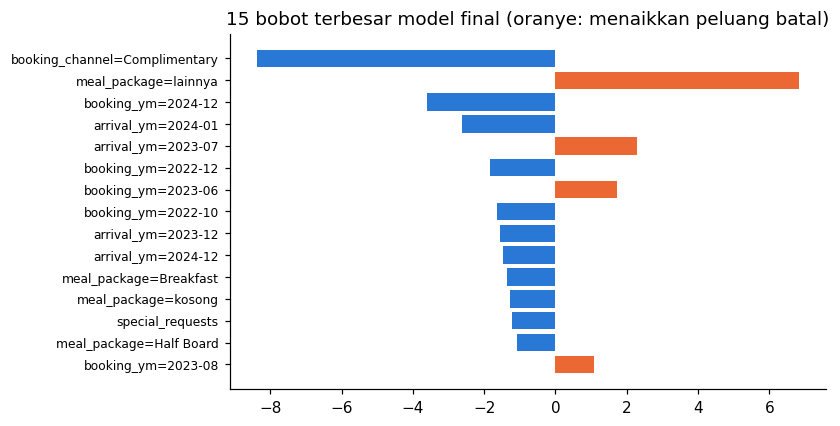

In [33]:
w = pd.Series(final_model.w, index=prep_full.feature_names_)
top = w.reindex(w.abs().sort_values(ascending=False).index)[:15]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index[::-1], top.values[::-1],
        color=[CFG.POS_COLOR if v > 0 else CFG.NEG_COLOR for v in top.values[::-1]])
ax.tick_params(axis='y', labelsize=8)
ax.set_title('15 bobot terbesar model final (oranye: menaikkan peluang batal)'); plt.show()

#### Insights

> Setelah fitur interaksi ditambahkan, kesalahan terbesar masih ada di ujung lead time. Untuk lead time 0 sampai 11 hari, tingkat batal aktual 9,4% tetapi model hanya memprediksi 2,3% batal (Macro F1 0,579), karena pembatalan mendadak hampir tidak punya sinyal di fitur yang tersedia. Untuk lead time 82 hari ke atas, model memprediksi terlalu banyak batal (40,2% terhadap 36,0% di Q4 dan 80,3% terhadap 73,6% di Q5), dengan FP rate tertinggi 16,8% di Q4. Per kanal, Offline Agent dan Online Travel Agent setara (Macro F1 0,78), Corporate lebih rendah (0,712) karena hanya 8,9% yang batal, dan Airline hanya 14 baris di `val_set` sehingga skornya tidak stabil.
>
> Bobot model final perlu dibaca hati-hati. Tanpa penalti, kolom one-hot saling kolinear dengan bias, sehingga bobot besar seperti `booking_channel=Complimentary` (−8,4) dan `meal_package=lainnya` (+6,8) hanya bermakna relatif terhadap kategori lain dalam fitur yang sama, bukan sebagai efek mutlak.

---

# Cost-Sensitive Classification (Bonus) <a name="12"></a>

---

Tidak semua kesalahan prediksi bernilai sama. **False Positive** (pesanan diprediksi batal padahal tamu datang) menyebabkan penginapan *overbooked*, sehingga diasumsikan **2 kali lebih mahal** daripada **False Negative** (pesanan diprediksi datang padahal batal, kamar hanya kosong). Prediksi benar tidak berbiaya. Matriks biaya:

| | prediksi tidak batal (0) | prediksi batal (1) |
|---|---|---|
| **aktual tidak batal (0)** | 0 (TN) | $C_{FP} = 2$ |
| **aktual batal (1)** | $C_{FN} = 1$ | 0 (TP) |

Tujuan berubah dari memaksimumkan Macro F1 menjadi **meminimumkan total biaya** $\text{Cost} = 2\cdot FP + 1\cdot FN$ [27].

**Cara kerja.** Logistic regression menghasilkan peluang $p = P(\text{batal} \mid x)$. Untuk satu pesanan, biaya harapan tiap keputusan adalah [27][28]:

- prediksi **batal**: salah hanya jika tamu ternyata datang, sehingga biaya harapan $= (1-p)\cdot C_{FP}$
- prediksi **tidak batal**: salah hanya jika tamu ternyata batal, sehingga biaya harapan $= p \cdot C_{FN}$

Keputusan optimal memilih biaya harapan terkecil, yaitu prediksi batal jika $(1-p)\,C_{FP} < p\,C_{FN}$, atau

$$p > p^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{2}{2+1} = \frac{2}{3}.$$

Dengan kata lain, model harus **lebih yakin** (peluang di atas 0,67, bukan 0,5) sebelum menyebut sebuah pesanan batal. Dua strategi dari Elkan [27] diuji:

1. **Threshold moving.** Model tidak diubah, hanya threshold keputusan yang digeser, baik ke nilai teori $p^* = 2/3$ maupun ke threshold empiris dengan biaya terkecil. Nilai teori hanya tepat jika peluang model terkalibrasi, sehingga kalibrasi diperiksa terlebih dahulu.
2. **Class weighting (rebalancing).** Biaya dimasukkan ke pelatihan dengan memberi bobot log-loss 2 pada kelas tidak batal dan 1 pada kelas batal (Teorema 2 Elkan: contoh negatif "digandakan" sebanyak rasio biaya), lalu memakai threshold 0,5. Secara teori ini setara dengan threshold 2/3 pada model tanpa bobot [27][29].

Threshold empiris dipilih dari probabilitas *out-of-fold* stratified 5-fold CV pada `train_set`, sehingga `val_set` tetap hanya dipakai untuk evaluasi akhir.

In [34]:
cw = {0: COST_FP, 1: COST_FN}   # bobot kelas = biaya salah klasifikasi kelas tersebut
oof = oof_proba(train_set, y_train, best_cfg)
oof_w = oof_proba(train_set, y_train, best_cfg, class_weight=cw)

t_theory = cost_threshold()
t_emp, _ = best_cost_threshold(y_train, oof)
t_emp_w, _ = best_cost_threshold(y_train, oof_w)
print(f'Threshold teori p* = {COST_FP:g} / ({COST_FP:g} + {COST_FN:g}) = {t_theory:.4f}')
print(f'Threshold empiris (OOF, tanpa bobot)        = {t_emp:.2f}')
print(f'Threshold empiris (OOF, class_weight {cw}) = {t_emp_w:.2f}')

# Cek kalibrasi: rata-rata peluang prediksi vs tingkat batal aktual per bin peluang (OOF train_set)
bins = pd.cut(oof, np.linspace(0, 1, 11))
pd.DataFrame({'p': oof, 'y': y_train}).groupby(bins, observed=True).agg(
    n=('y', 'size'), rata2_peluang=('p', 'mean'), tingkat_batal_aktual=('y', 'mean')).round(3)

Threshold teori p* = 2 / (2 + 1) = 0.6667
Threshold empiris (OOF, tanpa bobot)        = 0.63
Threshold empiris (OOF, class_weight {0: 2.0, 1: 1.0}) = 0.47


,n,rata2_peluang,tingkat_batal_aktual
"(0.0, 0.1]",6942,0.034,0.035
"(0.1, 0.2]",3203,0.148,0.148
"(0.2, 0.3]",2385,0.246,0.278
"(0.3, 0.4]",1519,0.350,0.316
"(0.4, 0.5]",1445,0.450,0.417
"(0.5, 0.6]",1486,0.551,0.564
"(0.6, 0.7]",1281,0.650,0.682
"(0.7, 0.8]",1286,0.750,0.740
"(0.8, 0.9]",1261,0.850,0.833
"(0.9, 1.0]",1039,0.953,0.944


#### Insights

> Peluang model terkalibrasi baik. Pada setiap bin, rata-rata peluang prediksi berselisih paling banyak sekitar 0,03 dari tingkat batal aktual (mis. bin 0,6 sampai 0,7: 0,650 terhadap 0,682). Threshold empiris dengan biaya terkecil (0,63) sedikit lebih rendah dari threshold teori 2/3 karena kurva biaya OOF sangat landai di daerah itu: total biaya OOF pada threshold 0,60 sampai 0,67 hanya berbeda sekitar 1% (5.279 sampai 5.339).

In [35]:
weighted_model = LogisticRegression(**best_cfg, **TRAIN_KW, class_weight=cw).fit(X_train, y_train)
pw_val = weighted_model.predict_proba(X_val)


def cost_row(name, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion(y_val, pred)
    return {'strategi': name, 'threshold': t, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'total_cost': total_cost(y_val, pred), 'cost_per_pesanan': total_cost(y_val, pred) / len(y_val),
            'precision_batal': tp / max(tp + fp, 1), 'recall_batal': tp / (tp + fn),
            'macro_f1': macro_f1(y_val, pred), 'accuracy': float(np.mean(pred == y_val))}


cost_table = pd.DataFrame([
    cost_row('baseline: semua tidak batal', p_val, 1.01),
    cost_row('default 0.5', p_val, 0.5),
    cost_row(f'threshold Macro F1 ({threshold:.2f})', p_val, threshold),
    cost_row('threshold teori 2/3', p_val, t_theory),
    cost_row(f'threshold empiris CV ({t_emp:.2f})', p_val, t_emp),
    cost_row('class_weight + 0.5', pw_val, 0.5),
    cost_row(f'class_weight + empiris CV ({t_emp_w:.2f})', pw_val, t_emp_w),
]).set_index('strategi')
cost_table.to_csv(CFG.OUTPUT_DIR / 'lr_cost_sensitive.csv')
cost_table.round(4)

,threshold,TN,FP,FN,TP,total_cost,cost_per_pesanan,precision_batal,recall_batal,macro_f1,accuracy
strategi,,,,,,,,,,,
baseline: semua tidak batal,1.0100,3673,0,1789,0,1789.0,0.3275,0.0000,0.0000,0.4021,0.6725
default 0.5,0.5000,3254,419,637,1152,1475.0,0.2700,0.7333,0.6439,0.7731,0.8067
threshold Macro F1 (0.46),0.4600,3174,499,539,1250,1537.0,0.2814,0.7147,0.6987,0.7830,0.8100
threshold teori 2/3,0.6667,3495,178,987,802,1343.0,0.2459,0.8184,0.4483,0.7182,0.7867
threshold empiris CV (0.63),0.6300,3452,221,911,878,1353.0,0.2477,0.7989,0.4908,0.7336,0.7927
class_weight + 0.5,0.5000,3494,179,986,803,1344.0,0.2461,0.8177,0.4489,0.7183,0.7867
class_weight + empiris CV (0.47),0.4700,3473,200,925,864,1325.0,0.2426,0.8120,0.4830,0.7331,0.7940


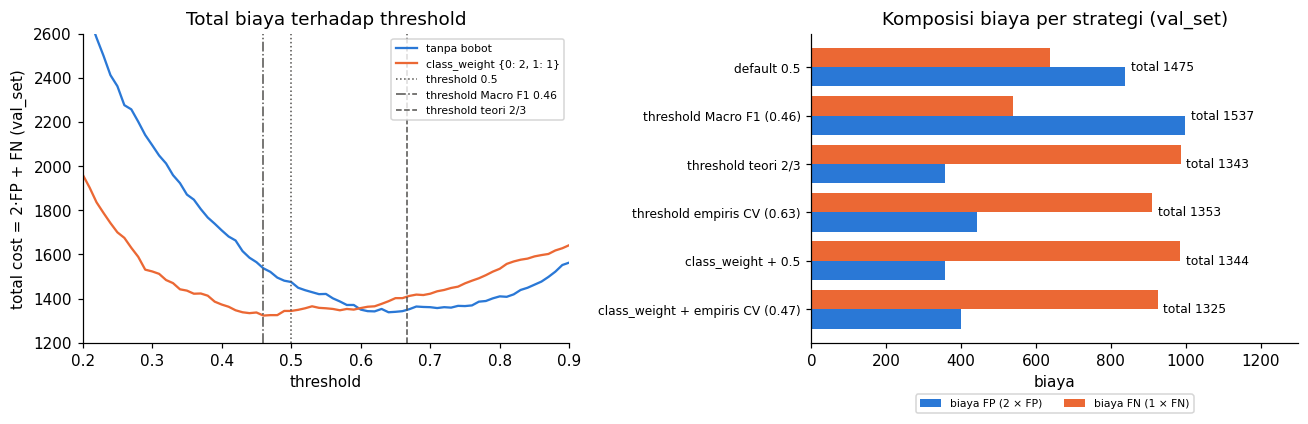

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for proba, label, color in [(p_val, 'tanpa bobot', CFG.NEG_COLOR),
                            (pw_val, 'class_weight {0: 2, 1: 1}', CFG.POS_COLOR)]:
    costs = [total_cost(y_val, (proba >= t).astype(int)) for t in COST_THRESHOLDS]
    axes[0].plot(COST_THRESHOLDS, costs, color=color, label=label)
for t, name, style in [(0.5, '0.5', ':'), (threshold, f'Macro F1 {threshold:.2f}', '-.'),
                       (t_theory, 'teori 2/3', '--')]:
    axes[0].axvline(t, color=CFG.MUTED, linestyle=style, linewidth=1, label=f'threshold {name}')
axes[0].set_xlabel('threshold'); axes[0].set_ylabel('total cost = 2·FP + FN (val_set)')
axes[0].set_xlim(0.2, 0.9); axes[0].set_ylim(1200, 2600)   # fokus ke sekitar titik minimum
axes[0].set_title('Total biaya terhadap threshold'); axes[0].legend(fontsize=7)

shown = cost_table.drop(index='baseline: semua tidak batal')
pos = np.arange(len(shown))
axes[1].barh(pos + 0.2, COST_FP * shown['FP'], height=0.4, color=CFG.NEG_COLOR, label='biaya FP (2 × FP)')
axes[1].barh(pos - 0.2, COST_FN * shown['FN'], height=0.4, color=CFG.POS_COLOR, label='biaya FN (1 × FN)')
for i, c in enumerate(shown['total_cost']):
    right = max(COST_FP * shown['FP'].iloc[i], COST_FN * shown['FN'].iloc[i])
    axes[1].text(right + 15, i, f'total {c:.0f}', va='center', fontsize=8)
axes[1].set_yticks(pos, shown.index, fontsize=8); axes[1].invert_yaxis()
axes[1].set_xlim(0, 1300)
axes[1].set_xlabel('biaya'); axes[1].set_title('Komposisi biaya per strategi (val_set)')
axes[1].legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout(); plt.show()

#### Insights

> - **Threshold yang dioptimalkan untuk Macro F1 justru lebih mahal.** Threshold 0,46 menambah prediksi batal sehingga FP naik ke 499 dan total biaya 1.537, lebih buruk daripada threshold 0,5 (1.475). Metrik yang mengabaikan biaya dapat mengarahkan ke keputusan yang salah.
> - **Menggeser threshold ke 2/3 menurunkan biaya 9%** (1.475 → 1.343). FP turun dari 419 ke 178, ditukar dengan FN yang naik dari 637 ke 987. Pertukaran ini menguntungkan karena satu FP yang dihindari bernilai dua FN. Threshold empiris CV (0,63) memberi hasil hampir sama (1.353), yang mengonfirmasi peluang model terkalibrasi.
> - **Class weighting dengan threshold 0,5 setara dengan threshold 2/3** (1.344 terhadap 1.343; FP 179 terhadap 178), sesuai Teorema 2 Elkan. Kombinasi class weight dengan threshold empiris CV (0,47) memberi biaya terendah di `val_set` (1.325, turun 10% dari threshold 0,5). Selisih antarstrategi cost-sensitive hanya sekitar 2%, sehingga yang terpenting adalah memasukkan biaya ke keputusan, bukan cara spesifiknya.
> - **Konsekuensinya**, precision kelas batal naik dari 0,73 ke 0,80 sampai 0,82, sedangkan recall turun dari 0,64 ke 0,45 sampai 0,49. Model menjadi konservatif: hanya pesanan dengan keyakinan batal tinggi yang ditandai, sehingga risiko *overbooking* turun walau lebih banyak kamar kosong yang tidak terantisipasi. Macro F1 dan accuracy turun, dan itu wajar karena tujuannya kini biaya, bukan F1.
> - **Rekomendasi:** untuk tujuan biaya, cukup gunakan model yang sama dengan threshold $p^* = C_{FP}/(C_{FP}+C_{FN})$. Cara ini sederhana, tidak perlu melatih ulang, dan mudah disesuaikan jika rasio biaya berubah. Submisi Kaggle tetap memakai threshold Macro F1 karena metrik kompetisi adalah Macro F1.

---

# Algoritma Optimasi: IRLS + Coordinate Descent (Bonus) <a name="13"></a>

---

Di kelas, bobot logistic regression dicari dengan (stochastic) gradient ascent [16]: bobot digeser sedikit demi sedikit searah gradien dengan learning rate tetap. Sebagai bonus, diimplementasikan algoritma yang dipakai **glmnet** [30]: **IRLS (Newton) + coordinate descent** (`solver="irls_cd"` di `lr.py`). Fungsi tujuannya sama persis dengan solver SGD, sehingga nilai `lam` dan `rho` tidak perlu dikonversi:

$$J(w,b) = \underbrace{-\frac{1}{n}\sum_i \big[y_i\log p_i + (1-y_i)\log(1-p_i)\big]}_{\text{log-loss}} + \lambda\Big[\rho\,\|w\|_1 + \frac{1-\rho}{2}\|w\|_2^2\Big]$$

**Bagaimana algoritma ini mengoptimasi model.** Satu iterasi terdiri atas dua langkah:

**1. IRLS: memakai kelengkungan, bukan hanya kemiringan [30, Sec. 3][31, Sec. 4.4.1].** Gradient descent hanya tahu *arah* turun (turunan pertama), sehingga besar langkah harus ditebak lewat learning rate. Newton's method juga memakai **turunan kedua** (seberapa melengkung permukaan loss), sehingga dapat memperkirakan langsung letak titik minimum. Caranya, log-loss diaproksimasi dengan deret Taylor orde 2 di sekitar parameter sekarang. Hasilnya adalah masalah *least squares berbobot*:

$$\min_{w,b}\; \frac{1}{2n}\sum_i s_i\,(z_i - b - x_i \cdot w)^2 + \text{penalti}, \qquad s_i = p_i(1-p_i), \quad z_i = \eta_i + \frac{y_i - p_i}{p_i(1-p_i)}$$

dengan $\eta_i = b + x_i\cdot w$. Bobot $s_i$ adalah turunan kedua log-loss, besar untuk contoh yang masih ragu ($p \approx 0{,}5$) dan kecil untuk contoh yang sudah yakin. Target kerja $z_i$ adalah prediksi sekarang ditambah koreksi error. Karena bobot dan target dihitung ulang setiap iterasi, metode ini disebut *Iteratively Reweighted Least Squares*. Di dekat optimum, Newton konvergen **kuadratik**: jumlah digit yang benar kira-kira berlipat dua setiap iterasi.

**2. Coordinate descent: menyelesaikan least squares berbobot satu bobot per langkah [30, Sec. 2].** Jika semua bobot lain dibuat tetap, masalah di atas untuk satu bobot $w_j$ berbentuk parabola yang punya solusi tertutup:

$$w_j \leftarrow \frac{S\big(g_j,\; \lambda\rho\big)}{h_j + \lambda(1-\rho)}, \qquad S(g, t) = \text{sign}(g)\,\max(|g| - t,\, 0)$$

dengan $g_j$ korelasi berbobot fitur $j$ dengan residual dan $h_j = \frac{1}{n}\sum_i s_i x_{ij}^2$. Operator **soft-thresholding** $S$ adalah cara yang benar menangani $|w|$ yang tidak terdiferensiasi di 0. Jika kontribusi fitur lebih kecil dari $\lambda\rho$, bobotnya menjadi **tepat nol**. Sebaliknya, solver SGD memakai subgradien $\text{sign}(w)$ sehingga bobot hanya berosilasi di sekitar nol. Agar cepat, update memakai *covariance updates* [30, Sec. 2.2]: matriks Gram berbobot $\frac{1}{n}A^\top S A$ berukuran 101 × 101 dihitung sekali per iterasi IRLS, sehingga setiap update hanya menyentuh 101 angka, bukan 21 ribu baris.

**Keuntungan dibanding SGD:** (1) konvergen dalam beberapa iterasi, bukan ratusan epoch; (2) tidak ada learning rate yang perlu dituning; (3) mencapai optimum yang sebenarnya; (4) penalti L1 menghasilkan bobot nol yang sesungguhnya (seleksi fitur otomatis). Solver juga ikut dituning pada `GRID` di validasi silang, sehingga konfigurasi final dipilih secara adil di antara kedua solver.

In [37]:
base_cfg = dict(penalty='l1', lam=1e-4, rho=0.5)   # L1 agar efek soft-thresholding (bobot tepat 0) terlihat
solver_models, rows = {}, []
for solver in ['sgd', 'irls_cd']:
    start = time.perf_counter()
    m = LogisticRegression(**base_cfg, **dict(TRAIN_KW, solver=solver)).fit(X_train, y_train)
    sec = time.perf_counter() - start
    proba = m.predict_proba(X_val)
    solver_models[solver] = m
    rows.append({'solver': solver, 'iterasi': len(m.loss_history), 'waktu_s': sec,
                 'J_akhir (train)': m.loss_history[-1], 'bobot_tepat_0': int(np.sum(m.w == 0)),
                 f'macro_f1@{threshold:.2f}': macro_f1(y_val, (proba >= threshold).astype(int)),
                 'roc_auc': report(y_val, proba, 0.5)['roc_auc']})

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sk_ref = sklearn_model(base_cfg, len(y_train)).fit(X_train, y_train)
j_sklearn = solver_models['irls_cd'].loss(X_train, y_train, sk_ref.coef_.ravel(), float(sk_ref.intercept_[0]))
print(f'Konfigurasi: {name_of(base_cfg)} | J optimum menurut scikit-learn: {j_sklearn:.6f}, '
      f'bobot tepat 0: {int(np.sum(sk_ref.coef_ == 0))}')
opt_table = pd.DataFrame(rows).set_index('solver')
opt_table.to_csv(CFG.OUTPUT_DIR / 'lr_optimizer_comparison.csv')
opt_table.round(6)

Konfigurasi: l1(lam=0.0001) | J optimum menurut scikit-learn: 0.408709, bobot tepat 0: 14


,iterasi,waktu_s,J_akhir (train),bobot_tepat_0,macro_f1@0.46,roc_auc
solver,,,,,,
sgd,100,1.655409,0.409511,2,0.779722,0.872606
irls_cd,8,3.907431,0.408706,16,0.781768,0.874089


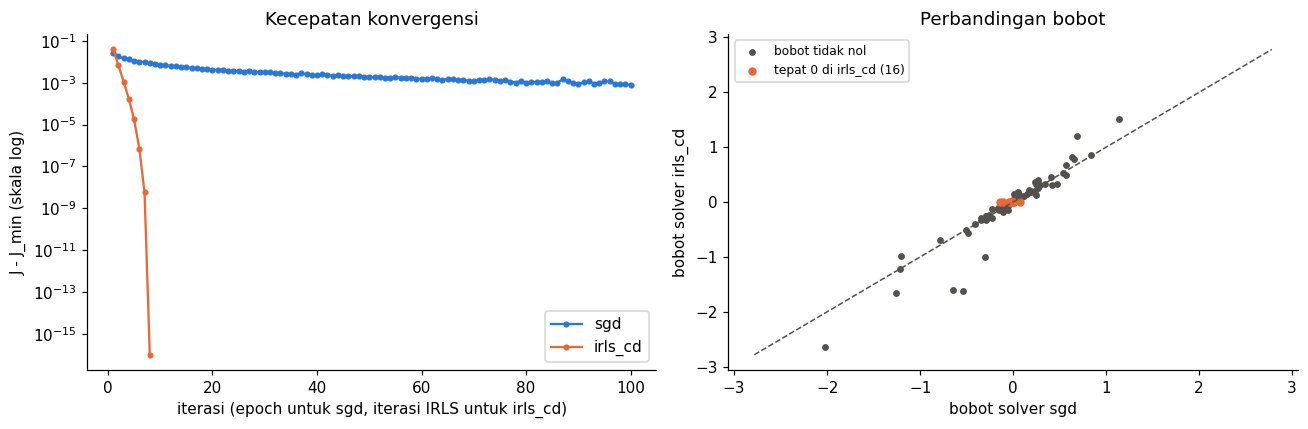

Fitur dengan bobot tepat 0 (irls_cd): ['lead_bin3_x_Airline', 'lead_bin4_x_Airline', 'meal_package=Room Only', 'meal_package=lainnya', 'room_category=Type D', 'room_category=lainnya', 'booking_channel=Complimentary', 'booking_channel=Online Travel Agent', 'arrival_ym=2023-10', 'arrival_ym=2023-11', 'arrival_ym=2024-04', 'arrival_ym=2024-08', 'booking_ym=2023-02', 'booking_ym=2023-09', 'booking_ym=2024-01', 'booking_ym=2024-11']


In [38]:
j_min = min(min(m.loss_history) for m in solver_models.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (solver, m), color in zip(solver_models.items(), [CFG.NEG_COLOR, CFG.POS_COLOR]):
    gap = np.maximum(np.array(m.loss_history) - j_min, 1e-16)
    axes[0].semilogy(np.arange(1, len(gap) + 1), gap, marker='o', markersize=3, color=color, label=solver)
axes[0].set_xlabel('iterasi (epoch untuk sgd, iterasi IRLS untuk irls_cd)')
axes[0].set_ylabel('J - J_min (skala log)')
axes[0].set_title('Kecepatan konvergensi'); axes[0].legend()

w_sgd, w_irls = solver_models['sgd'].w, solver_models['irls_cd'].w
zero = w_irls == 0
axes[1].scatter(w_sgd[~zero], w_irls[~zero], s=12, color=CFG.MUTED, label='bobot tidak nol')
axes[1].scatter(w_sgd[zero], w_irls[zero], s=20, color=CFG.POS_COLOR, label=f'tepat 0 di irls_cd ({zero.sum()})')
lim = np.abs(np.r_[w_sgd, w_irls]).max() * 1.05
axes[1].plot([-lim, lim], [-lim, lim], color=CFG.MUTED, linestyle='--', linewidth=1)
axes[1].set_xlabel('bobot solver sgd'); axes[1].set_ylabel('bobot solver irls_cd')
axes[1].set_title('Perbandingan bobot'); axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'lr_solver_convergence.png', dpi=150, bbox_inches='tight'); plt.show()
print('Fitur dengan bobot tepat 0 (irls_cd):', [prep.feature_names_[i] for i in np.flatnonzero(zero)])

#### Insights

> - **Konvergensi jauh lebih cepat.** Pada konfigurasi L1 λ = 10⁻⁴, IRLS-CD konvergen dalam 8 iterasi, sedangkan SGD berhenti di batas 100 epoch dan masih tertinggal sekitar 8 × 10⁻⁴ dari optimum. Jarak ke optimum pada IRLS-CD turun kira-kira kuadratik (3,9 × 10⁻² → 6,9 × 10⁻³ → 1,1 × 10⁻³ → 1,7 × 10⁻⁴ → 1,8 × 10⁻⁵ → 7,0 × 10⁻⁷ → 5,8 × 10⁻⁹). SGD butuh 78 epoch untuk mencapai loss IRLS-CD pada iterasi ke-3 dan tidak pernah mencapai loss iterasi ke-4. Satu iterasi IRLS-CD lebih berat daripada satu epoch SGD karena matriks Gram 101 × 101 dihitung ulang, sehingga waktu totalnya tetap beberapa detik (3,9 s terhadap 1,9 s).
> - **Mencapai optimum yang sebenarnya.** Nilai akhir J IRLS-CD (0,408706) bahkan sedikit di bawah J pada solusi scikit-learn (0,408709), sedangkan SGD berhenti di 0,409511.
> - **Seleksi fitur otomatis.** IRLS-CD menghasilkan 16 bobot tepat nol (scikit-learn 14). SGD hanya punya 2 bobot nol, yaitu `lead_bin3_x_Airline` dan `lead_bin4_x_Airline`. Keduanya kolom yang selalu nol karena tidak ada pesanan Airline dengan lead time di atas 30 hari, sehingga gradiennya selalu nol. Bobot lain pada SGD hanya berosilasi di sekitar nol karena subgradien. Fitur yang dibuang IRLS-CD antara lain `meal_package=Room Only`, `room_category=Type D`, `booking_channel=Online Travel Agent`, dan beberapa bulan `arrival_ym`/`booking_ym` yang tidak informatif.
> - **Performa sedikit lebih baik.** Di `val_set`, Macro F1 0,7818 terhadap 0,7797 dan ROC-AUC 0,8741 terhadap 0,8726. Pada validasi silang, IRLS-CD lebih tinggi untuk semua penalti lemah (tanpa penalti dan λ = 10⁻⁴), dan Macro F1 OOF terbaik naik dari 0,7814 (SGD) ke 0,7824. Pada λ ≥ 10⁻³ kedua solver berselisih paling besar 0,0007. Kenaikannya kecil karena logistic regression bersifat konveks: kedua solver menuju optimum yang sama, hanya SGD yang belum sepenuhnya sampai. Karena itu konfigurasi final dan submisi Kaggle memakai `solver="irls_cd"`.

---

# Video Kontur Log-Loss (Bonus) <a name="14"></a>

---

Video ini menampilkan garis kontur fungsi loss $J(\theta_0, \theta_1)$ (log-loss) dan lintasan parameter $(\theta_0, \theta_1)$ selama training (`src/algoritma/lr/contour_video.py`).

Model final memiliki 100 bobot sehingga permukaan loss-nya tidak dapat digambar pada bidang 2D. Karena itu dilatih logistic regression dengan **tepat dua parameter** memakai kelas `LogisticRegression` yang sama: $\theta_0$ adalah bias dan $\theta_1$ adalah bobot `lead_log` (lead time yang sudah di-log dan distandardisasi, fitur tunggal terkuat), yaitu $P(\text{batal}) = \sigma(\theta_0 + \theta_1 x)$. Dengan begitu kontur adalah permukaan log-loss yang sebenarnya, bukan irisan, dan setiap titik lintasan adalah parameter yang disimpan model (`model.path`) setelah setiap epoch [16][32].

Model dilatih dengan gradient descent sesuai materi kelas [16] (`solver="sgd"` tanpa `batch_size`, sehingga setiap epoch memakai gradien seluruh data, dengan lr = 0,5). Titik awal $(\theta_0, \theta_1) = (1{,}5;\ 0{,}5)$ dipilih di luar $(0, 0)$ agar bentuk lintasan terlihat jelas, karena menurut [16] inisialisasi boleh selain nol.

Video tersimpan: ..\..\output\lr\lr_contour.mp4 | frame terakhir video ditampilkan di bawah
epoch: 127 | theta0 = -0.9319, theta1 = 1.0999, J akhir = 0.551186


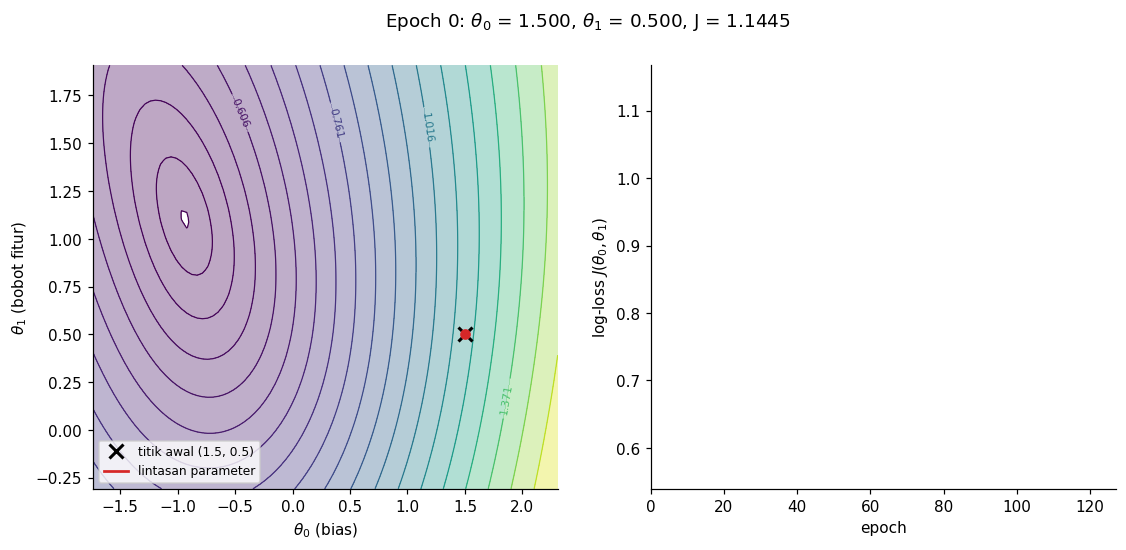

In [39]:
contour_x = X_train[:, prep.feature_names_.index('lead_log')]
CONTOUR_INIT = (1.5, 0.5)          # (theta0, theta1) awal
contour_model = train_2param(contour_x, y_train, CONTOUR_INIT, lr=0.5, n_epochs=300, tol=1e-7)
fig, video_path = make_video(contour_x, y_train, contour_model, CONTOUR_INIT, CFG.OUTPUT_DIR / 'lr_contour')
fig.savefig(CFG.OUTPUT_DIR / 'lr_contour.png', dpi=130, bbox_inches='tight')
print('Video tersimpan:', video_path, '| frame terakhir video ditampilkan di bawah')
print(f'epoch: {len(contour_model.path)} | theta0 = {contour_model.b:.4f}, theta1 = {contour_model.w[0]:.4f}, '
      f'J akhir = {contour_model.loss_history[-1]:.6f}')

#### Insights

> - **Bentuk permukaan loss.** Log-loss dua parameter ini konveks dengan satu minimum di $(\theta_0, \theta_1) \approx (-0{,}93;\ 1{,}10)$, $J_{min} \approx 0{,}5512$. Konturnya berupa elips miring dan memanjang: permukaan curam ke arah $\theta_0$ tetapi landai di sepanjang lembah elips.
> - **Lintasan gradient descent.** Setiap langkah tegak lurus garis kontur (arah gradien), sehingga lintasannya melengkung. Pada epoch-epoch awal parameter turun cepat ke dasar lembah, terutama dengan mengoreksi bias $\theta_0$ dari 1,5 ke sekitar −0,7. Setelah itu lintasan berbelok dan merayap pelan di sepanjang lembah sambil menaikkan $\theta_1$ hingga sekitar 1,10. Loss turun tajam di awal lalu melandai, dan training berhenti setelah 127 epoch ketika perubahan loss di bawah toleransi $10^{-7}$.
> - **Makna hasil akhir.** $\theta_1 > 0$ berarti peluang batal naik seiring lead time, sesuai EDA. $\theta_0 \approx -0{,}93$ setara peluang batal sekitar 28% untuk lead time rata-rata. Langkah yang makin kecil di sepanjang lembah yang landai adalah alasan gradient descent butuh banyak epoch, dan inilah yang dipercepat oleh IRLS-CD pada bagian 13.
>
> Video tersimpan di `output/lr/lr_contour.mp4`, dan frame terakhirnya di `output/lr/lr_contour.png`.

---

## Referensi

- [15] M. L. Khodra, "Logistic Regression: What & Why," YouTube, 2021. https://www.youtube.com/watch?v=QAKZ_pymEzc
- [16] M. L. Khodra, "Logistic Regression: Stochastic Gradient Ascent," YouTube, 2021. https://www.youtube.com/watch?v=O5NSNMQO1yU
- [26] GeeksforGeeks, "Logistic Regression in Machine Learning." https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/
- scikit-learn User Guide, "Logistic regression." https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
- R. Tibshirani, "Regression Shrinkage and Selection via the Lasso," J. R. Stat. Soc. B, 58(1), 1996.
- H. Zou and T. Hastie, "Regularization and Variable Selection via the Elastic Net," J. R. Stat. Soc. B, 67(2), 2005.
- [27] C. Elkan, "The Foundations of Cost-Sensitive Learning," in *Proc. 17th Int. Joint Conf. Artificial Intelligence (IJCAI)*, 2001, pp. 973-978.
- [28] C. M. Bishop, *Pattern Recognition and Machine Learning*. New York: Springer, 2006, Sec. 1.5.2 "Minimizing the expected loss."
- [29] scikit-learn User Guide, "Tuning the decision threshold for class prediction" dan parameter `class_weight` pada `LogisticRegression`. https://scikit-learn.org/stable/modules/classification_threshold.html
- S. Galli, "Cost-Sensitive Learning (CSL) - Machine Learning with Imbalanced Data," Train in Data, YouTube. https://youtu.be/LbhJ4gYoKxA
- Dr. Data Science, "Machine Learning with Imbalanced Data - Part 2 (Cost-sensitive Learning)," YouTube. https://youtu.be/vJkWB_kmadQ
- [30] J. Friedman, T. Hastie, and R. Tibshirani, "Regularization Paths for Generalized Linear Models via Coordinate Descent," *Journal of Statistical Software*, vol. 33, no. 1, pp. 1-22, 2010.
- [31] T. Hastie, R. Tibshirani, and J. Friedman, *The Elements of Statistical Learning*, 2nd ed. New York: Springer, 2009, Sec. 4.4.1 "Fitting Logistic Regression Models."
- [32] Matplotlib Developers, "matplotlib.animation" dan "matplotlib.pyplot.contour," Matplotlib documentation. https://matplotlib.org/stable/api/animation_api.html